# Load preprocessed Dataset

In [1]:
import pandas as pd

file_path = '/home/abhajkhan/Code/mca-tkmce/bipolar-disorder-severity-assessment-system/notebooks/Bipolar_preprocessed.csv'
df = pd.read_csv(file_path)
df = df.copy() # defragment dataframe

display(df.head())

/usr/lib/python3/dist-packages/pytz/__init__.py:31: SyntaxWarning: invalid escape sequence '\s'
  match = re.match("^#\s*version\s*([0-9a-z]*)\s*$", line)


,age,age_onset,total_number_of_episodes,total_duration_of_illness_in_months,total_duration_of_all_episodes_in_months,total_duration_of_hypomanic_episodes_in_months,total_number_of_manic_episodes,total_number_of_hypomanic_episodes,total_number_of_mixed_episodes,total_number_of_depressive_episodes,...,antipsychotic_Olanzapine,antipsychotic_Risperidone,antipsychotic_Unknown,education_standard_Illiterate,education_standard_Other/Unknown,education_standard_Postgraduate,education_standard_Primary/Secondary,education_standard_Secondary/Pre-University,education_standard_Undergraduate,education_standard_Unknown
0,0.532967,0.293343,0.010967,0.692430,0.041212,0.139536,0.374633,0.209127,0.054453,0.003024,...,False,False,False,False,False,False,True,False,False,False
1,0.767857,0.644235,0.005982,0.598200,0.012910,0.031978,0.280829,0.033378,0.054453,0.003024,...,False,False,True,False,True,False,False,False,False,False
2,0.506868,0.346951,0.006979,0.583025,0.006951,0.031978,0.343365,0.033378,0.054453,0.002022,...,False,False,False,False,False,False,False,False,True,False
3,0.644231,0.507777,0.005982,0.584966,0.006951,0.031978,0.280829,0.033378,0.054453,0.003024,...,False,False,False,True,False,False,False,False,False,False
4,0.520604,0.361572,0.010967,0.585848,0.015889,0.031978,0.437170,0.033378,0.054453,0.003024,...,False,False,False,False,True,False,False,False,False,False


## Features used for clustering


In [2]:
# Features used for clustering
df_clustering = df.drop(columns=['cluster_label'], errors='ignore')

print(f"Number of features used for clustering: {df_clustering.shape[1]}")

Number of features used for clustering: 168


# Hierarchical Clustering (Agglomerative Clustering)

Now, I will perform Hierarchical Clustering using `AgglomerativeClustering`. To determine the optimal number of clusters, I will first use a dendrogram. After identifying a suitable number of clusters, I will apply the clustering algorithm.

## HIERARCHICAL: EVALUATE k = 2...10


In [3]:
# ============================================================
# HIERARCHICAL: EVALUATE k = 2...10
# ============================================================

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
import pandas as pd

hierarchical_results = []

for k in range(2, 11):

    model = AgglomerativeClustering(
        n_clusters=k,
        metric="euclidean",
        linkage="ward"
    )

    labels = model.fit_predict(df_clustering)

    hierarchical_results.append({
        "k": k,
        "Silhouette": silhouette_score(df_clustering, labels),
        "Davies_Bouldin": davies_bouldin_score(df_clustering, labels),
        "Calinski_Harabasz": calinski_harabasz_score(
            df_clustering,
            labels
        )
    })

hierarchical_results = pd.DataFrame(hierarchical_results)

print("HIERARCHICAL CLUSTERING RESULTS")
display(hierarchical_results.round(6))

print("\nBest k according to each metric:")

print(
    "Maximum Silhouette:",
    hierarchical_results.loc[
        hierarchical_results["Silhouette"].idxmax()
    ].to_dict()
)

print(
    "Minimum Davies-Bouldin:",
    hierarchical_results.loc[
        hierarchical_results["Davies_Bouldin"].idxmin()
    ].to_dict()
)

print(
    "Maximum Calinski-Harabasz:",
    hierarchical_results.loc[
        hierarchical_results["Calinski_Harabasz"].idxmax()
    ].to_dict()
)

HIERARCHICAL CLUSTERING RESULTS


,k,Silhouette,Davies_Bouldin,Calinski_Harabasz
0,2,0.364764,0.888365,123.547208
1,3,0.245421,1.645275,114.865810
2,4,0.267813,1.394553,111.896884
3,5,0.273307,1.391421,94.675948
4,6,0.280463,1.359072,80.667855
5,7,0.191549,2.171854,70.610061
6,8,0.187446,2.294634,62.567369
7,9,0.187242,2.297877,56.334016
8,10,0.188965,2.345496,51.128906



Best k according to each metric:
Maximum Silhouette: {'k': 2.0, 'Silhouette': 0.3647639900764888, 'Davies_Bouldin': 0.8883650471109892, 'Calinski_Harabasz': 123.54720833905269}
Minimum Davies-Bouldin: {'k': 2.0, 'Silhouette': 0.3647639900764888, 'Davies_Bouldin': 0.8883650471109892, 'Calinski_Harabasz': 123.54720833905269}
Maximum Calinski-Harabasz: {'k': 2.0, 'Silhouette': 0.3647639900764888, 'Davies_Bouldin': 0.8883650471109892, 'Calinski_Harabasz': 123.54720833905269}


### Dendrogram

In [4]:
# ============================================================
# HIERARCHICAL: DENDROGRAM / MERGE DISTANCE INFORMATION
# ============================================================

from scipy.cluster.hierarchy import linkage
import pandas as pd

linked_data = linkage(
    df_clustering,
    method="ward"
)

print("Linkage matrix shape:")
print(linked_data.shape)

print("\nLast 15 merge distances:")
display(
    pd.DataFrame(
        linked_data[-15:],
        columns=[
            "cluster_1",
            "cluster_2",
            "distance",
            "cluster_size"
        ]
    ).round(6)
)

# For n=342 observations:
# 3 clusters require 342 - 3 = 339 merges.
# Therefore the merge creating the transition from 4 -> 3
# occurs at index 338 (0-based).

n_samples = len(df_clustering)

merge_index_for_3_clusters = n_samples - 3 - 1

print(
    "\nMerge distance associated with transition to 3 clusters:"
)

print(
    linked_data[merge_index_for_3_clusters, 2]
)

Linkage matrix shape:
(341, 4)

Last 15 merge distances:


,cluster_1,cluster_2,distance,cluster_size
0,643.0,665.0,7.837333,41.0
1,613.0,667.0,8.368649,40.0
2,659.0,663.0,8.393770,32.0
3,650.0,662.0,8.613841,45.0
4,658.0,668.0,8.994545,71.0
5,664.0,671.0,9.087238,77.0
6,645.0,670.0,9.092394,43.0
7,653.0,674.0,10.486735,64.0
8,661.0,675.0,11.254121,97.0
9,672.0,676.0,13.537787,168.0



Merge distance associated with transition to 3 clusters:
36.62322461954598


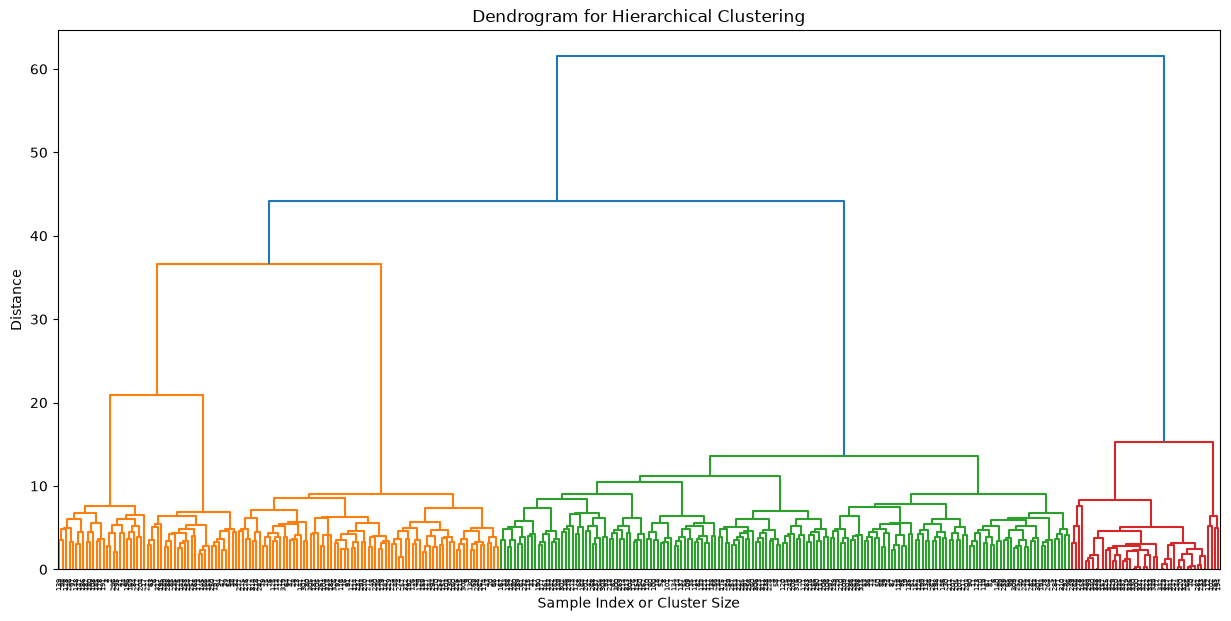

In [5]:
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

# Generate the linkage matrix
linked_data = linkage(df_clustering, method='ward') # 'ward' minimizes the variance within each cluster

# Plot the dendrogram
plt.figure(figsize=(15, 7))
dendrogram(linked_data,
           orientation='top',
           distance_sort='descending',
           show_leaf_counts=True)
plt.title('Dendrogram for Hierarchical Clustering')
plt.xlabel('Sample Index or Cluster Size')
plt.ylabel('Distance')
plt.show()

Based on the dendrogram, you can visually inspect for a suitable number of clusters (e.g., by looking for the longest vertical line that doesn't intersect any clusters). Let's assume an initial number of clusters, say `k=3` for demonstration, but you should adjust this based on the dendrogram. I'll add a placeholder for the number of clusters, which you can adjust later.

# Agglomerative Clustering (n_cluster=3)

In [6]:
from sklearn.cluster import AgglomerativeClustering

n_clusters = 3 # Adjust this value based on dendrogram or domain knowledge

# Apply Agglomerative Clustering
agglomerative_clustering = AgglomerativeClustering(n_clusters=n_clusters, metric='euclidean', linkage='ward')
df['cluster_label'] = agglomerative_clustering.fit_predict(df_clustering)

print(f"Assigned {n_clusters} clusters to the data.")
display(df.head())

Assigned 3 clusters to the data.


,age,age_onset,total_number_of_episodes,total_duration_of_illness_in_months,total_duration_of_all_episodes_in_months,total_duration_of_hypomanic_episodes_in_months,total_number_of_manic_episodes,total_number_of_hypomanic_episodes,total_number_of_mixed_episodes,total_number_of_depressive_episodes,...,antipsychotic_Risperidone,antipsychotic_Unknown,education_standard_Illiterate,education_standard_Other/Unknown,education_standard_Postgraduate,education_standard_Primary/Secondary,education_standard_Secondary/Pre-University,education_standard_Undergraduate,education_standard_Unknown,cluster_label
0,0.532967,0.293343,0.010967,0.692430,0.041212,0.139536,0.374633,0.209127,0.054453,0.003024,...,False,False,False,False,False,True,False,False,False,2
1,0.767857,0.644235,0.005982,0.598200,0.012910,0.031978,0.280829,0.033378,0.054453,0.003024,...,False,True,False,True,False,False,False,False,False,2
2,0.506868,0.346951,0.006979,0.583025,0.006951,0.031978,0.343365,0.033378,0.054453,0.002022,...,False,False,False,False,False,False,False,True,False,0
3,0.644231,0.507777,0.005982,0.584966,0.006951,0.031978,0.280829,0.033378,0.054453,0.003024,...,False,False,True,False,False,False,False,False,False,0
4,0.520604,0.361572,0.010967,0.585848,0.015889,0.031978,0.437170,0.033378,0.054453,0.003024,...,False,False,False,True,False,False,False,False,False,2


In [7]:
# Count the number of records in each cluster
cluster_counts = df['cluster_label'].value_counts().sort_index()
print("Number of records in each cluster:")
display(cluster_counts)

Number of records in each cluster:


cluster_label
0    130
1     44
2    168
Name: count, dtype: int64

### Cluster Evaluation Metrics

Now, I will evaluate the created clusters using three popular metrics:
1.  **Silhouette Score**: Measures how similar an object is to its own cluster compared to other clusters. Higher values indicate better-defined clusters.
2.  **Davies-Bouldin Index**: Measures the average similarity ratio of each cluster with its most similar cluster. Lower values indicate better separation between clusters.
3.  **Calinski-Harabasz Index (Variance Ratio Criterion)**: Measures the ratio of between-cluster dispersion to within-cluster dispersion. Higher values generally indicate better-defined clusters.

In [8]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Ensure there are at least 2 clusters for silhouette_score to be defined
if n_clusters > 1:
    # Calculate Silhouette Score
    silhouette = silhouette_score(df_clustering, df['cluster_label'])
    print(f"Silhouette Score: {silhouette:.3f}")

    # Calculate Davies-Bouldin Index
    davies_bouldin = davies_bouldin_score(df_clustering, df['cluster_label'])
    print(f"Davies-Bouldin Index: {davies_bouldin:.3f}")

    # Calculate Calinski-Harabasz Index
    calinski_harabasz = calinski_harabasz_score(df_clustering, df['cluster_label'])
    print(f"Calinski-Harabasz Index: {calinski_harabasz:.3f}")
else:
    print("Cannot compute evaluation metrics for a single cluster (n_clusters must be > 1).")

Silhouette Score: 0.245
Davies-Bouldin Index: 1.645
Calinski-Harabasz Index: 114.866


### Identifying Differentiating Features

To understand what differentiates each cluster, I will analyze the mean values of the original features within each cluster. This will help us identify which features have significantly different average values across the clusters, indicating their importance in defining the clusters.

In [9]:
import seaborn as sns

# Group by cluster and calculate the mean of each numerical feature
cluster_means = df.groupby('cluster_label')[numerical_cols].mean()
display(cluster_means)


NameError: name 'numerical_cols' is not defined

In [ ]:
overall_means = df[numerical_cols].mean()
print("Overall mean of each numerical feature:")
display(overall_means)

In [ ]:
# Calculate the difference between cluster means and overall means
mean_differences = cluster_means - overall_means
print("Difference of cluster means from overall feature means:")
display(mean_differences)

# Or, to see percentage difference (optional, might be more intuitive for some)
percentage_differences = (mean_differences / overall_means) * 100
print("Percentage difference of cluster means from overall feature means:")
display(percentage_differences)

Figures will be saved to: /home/abhajkhan/Code/mca-tkmce/bipolar-disorder-severity-assessment-system/notebooks/ppt_outputs/hierarchical


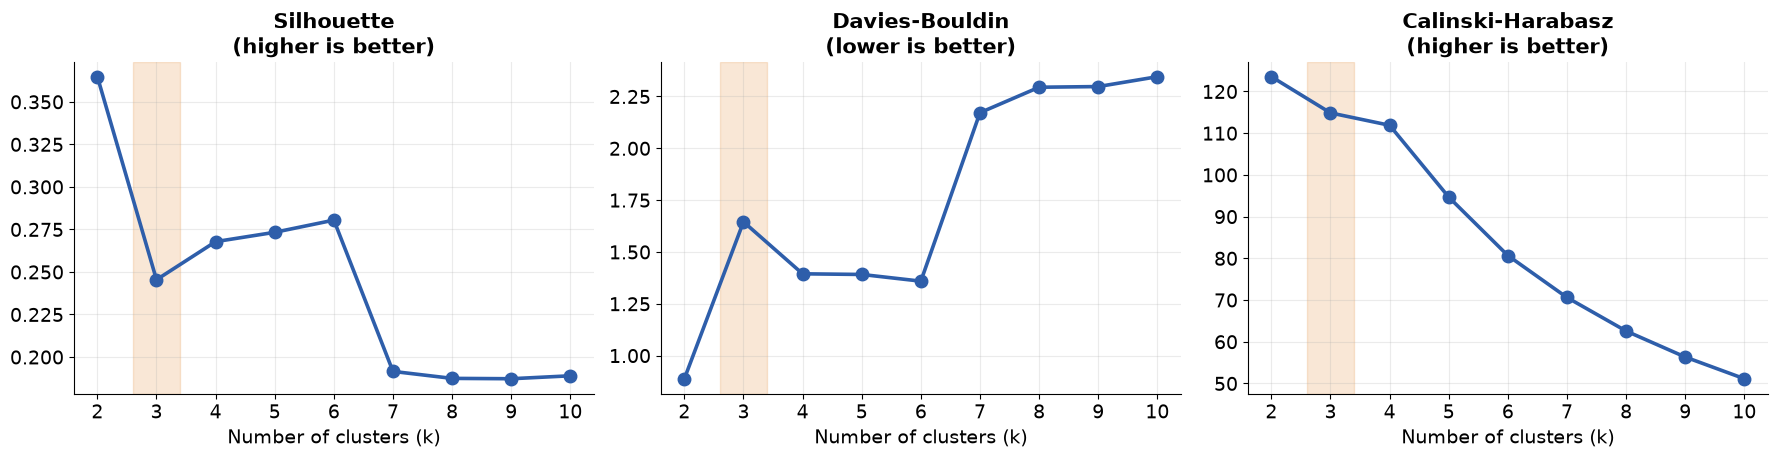

saved -> ppt_outputs/hierarchical/01_validation_indices.png


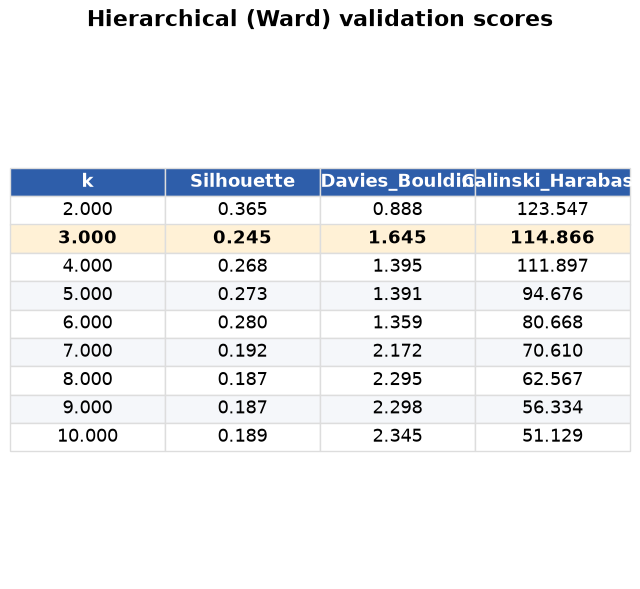

saved -> ppt_outputs/hierarchical/02_metric_table.png


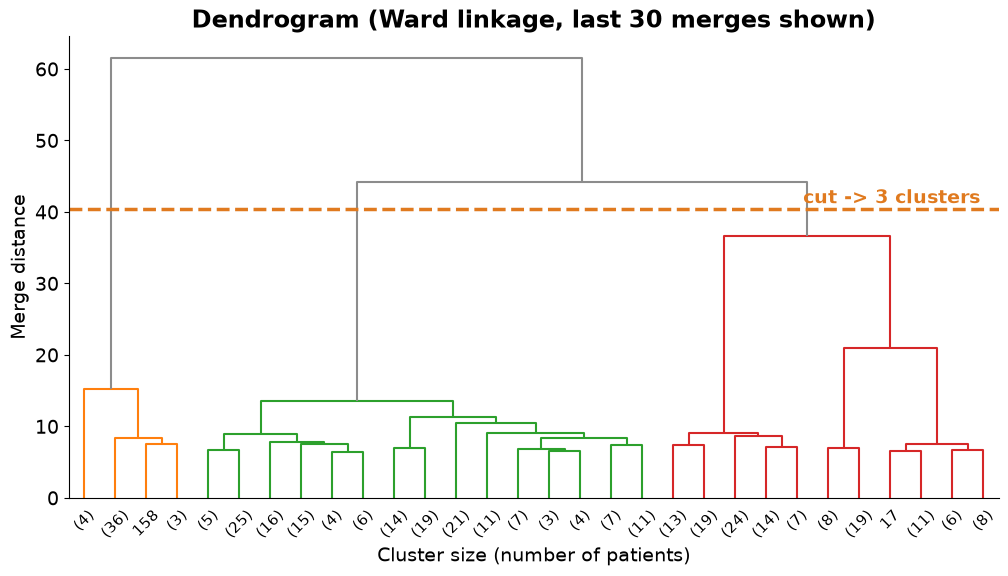

saved -> ppt_outputs/hierarchical/03_dendrogram.png


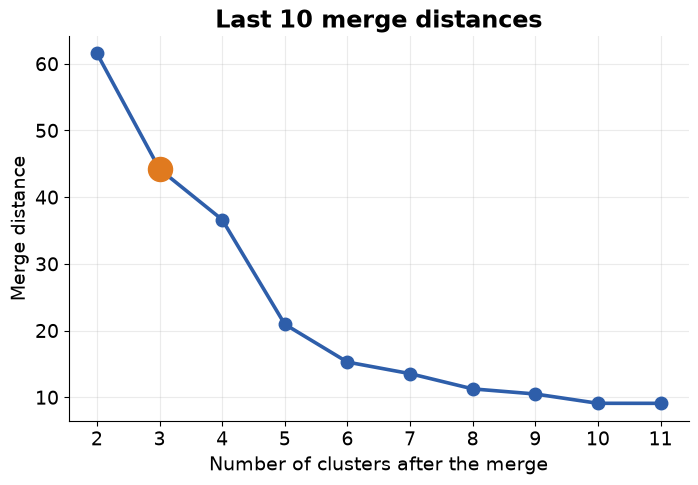

saved -> ppt_outputs/hierarchical/04_merge_distances.png
   Manic  Depressive  Unknown
0  0.759       0.150    0.242
1  0.019       0.061    0.758
2  0.747       0.561    0.011


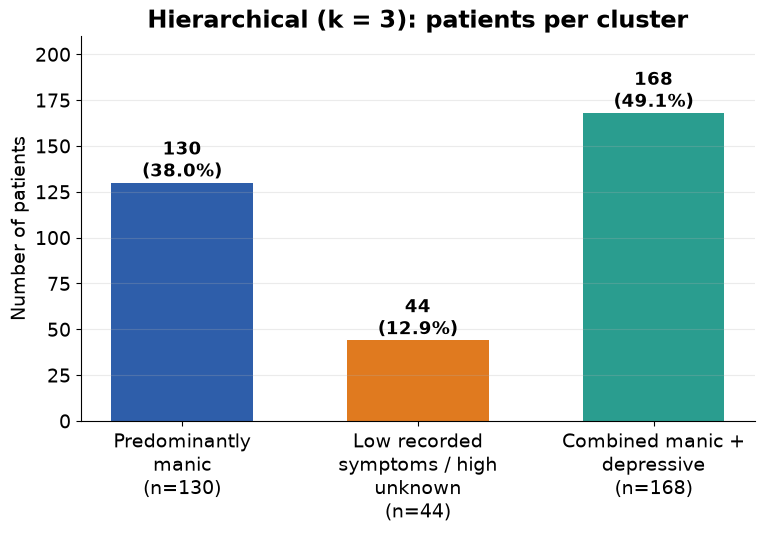

saved -> ppt_outputs/hierarchical/05_cluster_sizes.png


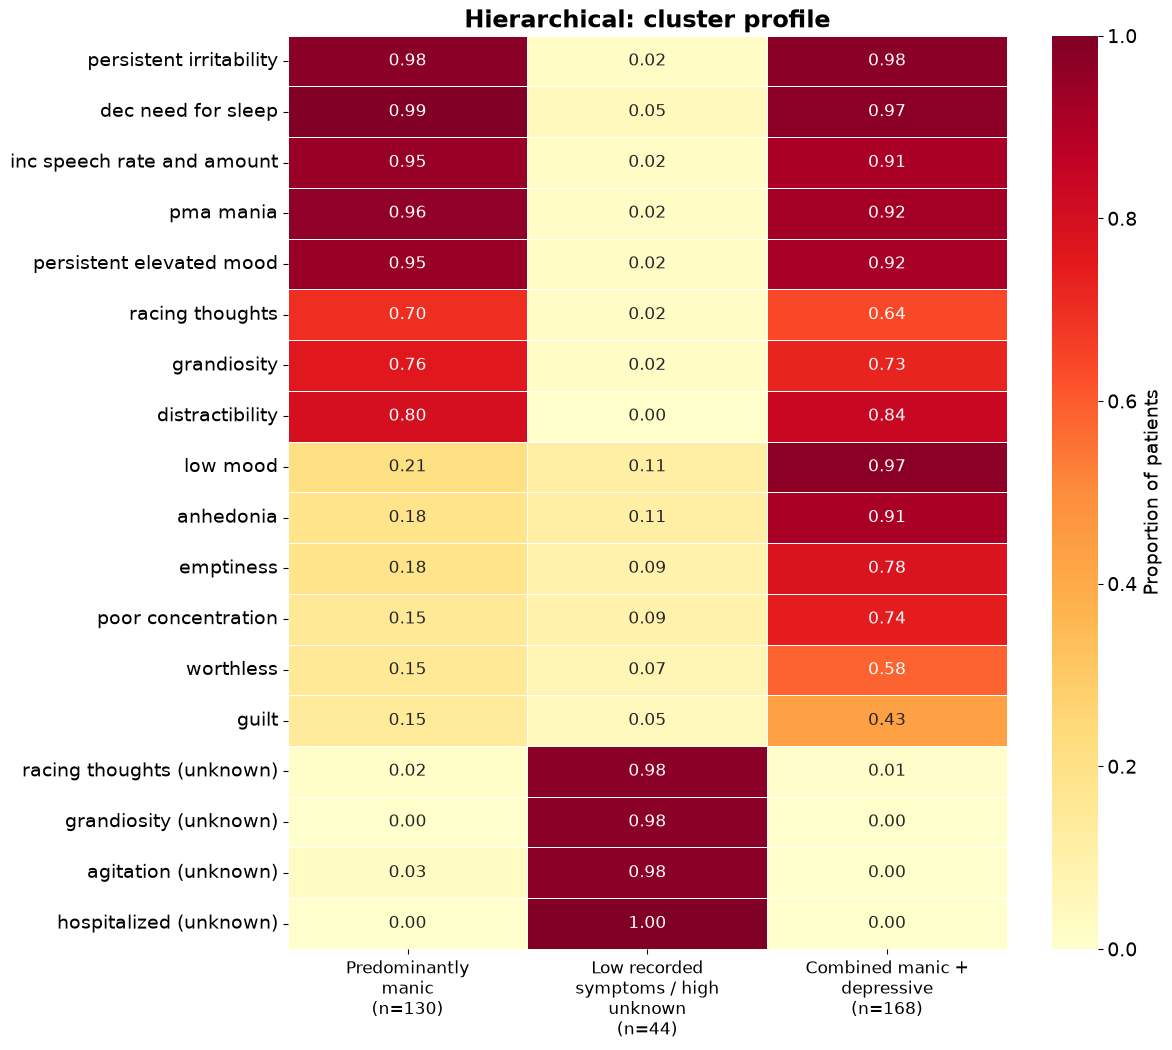

saved -> ppt_outputs/hierarchical/06_profile_heatmap.png
11 manic, 9 depressive, 64 unknown-indicator columns used


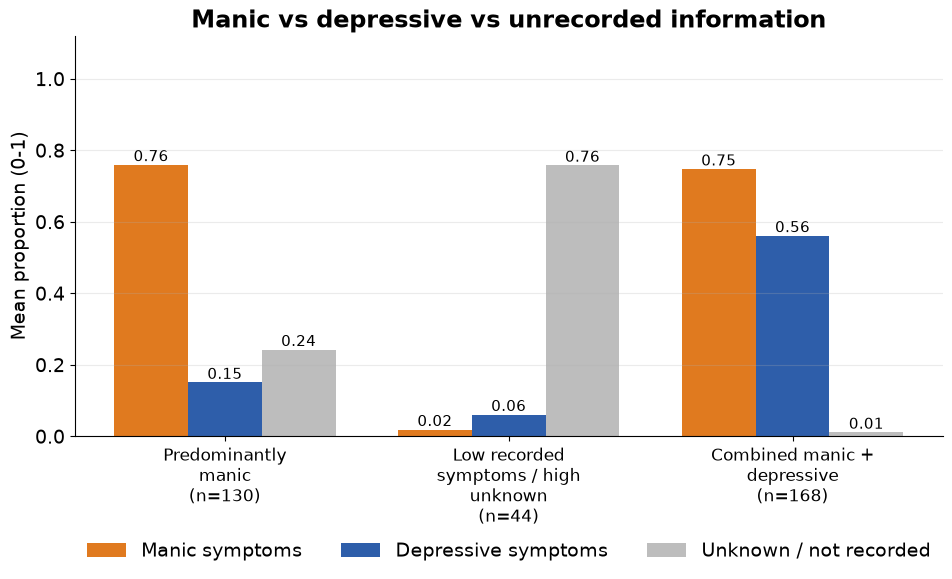

saved -> ppt_outputs/hierarchical/07_symptom_summary.png


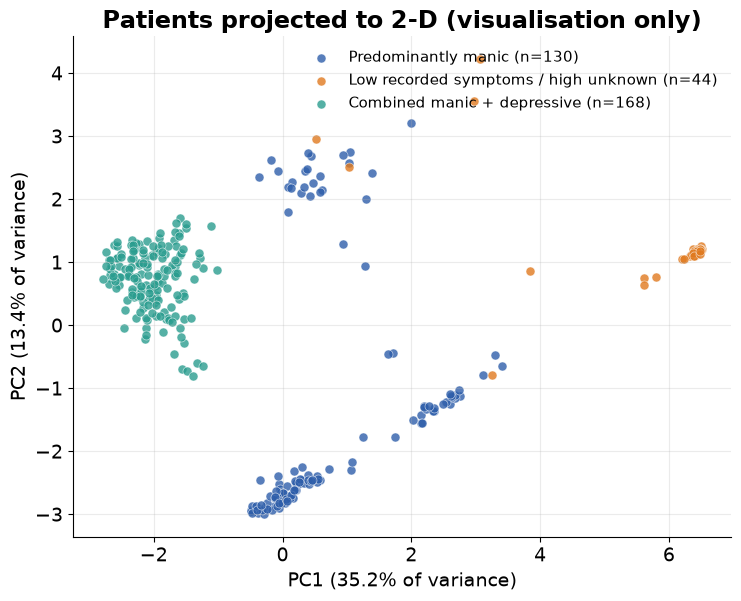

saved -> ppt_outputs/hierarchical/08_pca_scatter.png


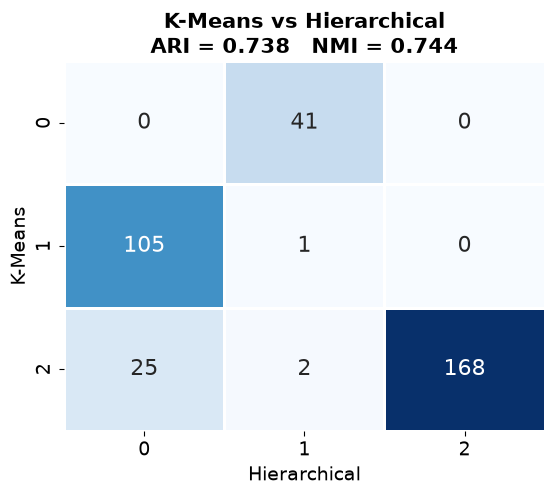

saved -> ppt_outputs/hierarchical/09_kmeans_vs_hier.png


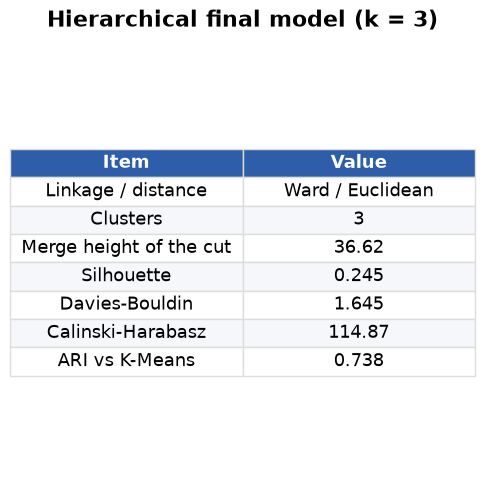

saved -> ppt_outputs/hierarchical/10_key_numbers.png


In [10]:
# ===== Append to the END of BD_Hierarchical_Cluster notebook =====
# %% CELL 1 - setup + metrics k = 2..10
from ppt_helpers import *
from sklearn.cluster import AgglomerativeClustering, KMeans
from scipy.cluster.hierarchy import linkage, dendrogram
setup("hierarchical")

X = feature_matrix(df)
rows = []
for k in range(2, 11):
    l = AgglomerativeClustering(n_clusters=k, metric="euclidean", linkage="ward").fit_predict(X)
    rows.append(dict(k=k, Silhouette=silhouette_score(X, l),
                     Davies_Bouldin=davies_bouldin_score(X, l),
                     Calinski_Harabasz=calinski_harabasz_score(X, l)))
res = pd.DataFrame(rows)
metric_panel(res, "01_validation_indices", highlight_k=3)
table_png(res, "02_metric_table", title="Hierarchical (Ward) validation scores",
          highlight_rows=[list(res.k).index(3)])

# %% CELL 2 - readable dendrogram with the 3-cluster cut line
Z = linkage(X, method="ward")
cut = (Z[-3, 2] + Z[-2, 2]) / 2            # height that leaves exactly 3 clusters
fig, ax = plt.subplots(figsize=(12, 6))
dendrogram(Z, truncate_mode="lastp", p=30, color_threshold=cut, show_leaf_counts=True,
           leaf_font_size=11, above_threshold_color="#8C8C8C", ax=ax)
ax.axhline(cut, color=HILITE, ls="--", lw=2.5)
ax.text(ax.get_xlim()[1] * 0.98, cut * 1.02, "cut -> 3 clusters", color=HILITE,
        ha="right", fontsize=14, weight="bold")
ax.set_title("Dendrogram (Ward linkage, last 30 merges shown)")
ax.set_xlabel("Cluster size (number of patients)"); ax.set_ylabel("Merge distance")
ax.grid(False)
save("03_dendrogram")

# %% CELL 3 - merge-distance plot (supports the choice of 3)
dist = Z[-10:, 2][::-1]                  # distances of the last 10 merges
clusters_left = np.arange(2, 12)[:10]    # merge that leaves 2,3,...,11 clusters
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(clusters_left, dist, marker="o", lw=2.6, ms=9, color=COLORS[0])
ax.scatter([3], [dist[1]], s=300, color=HILITE, zorder=5)
ax.set_xlabel("Number of clusters after the merge"); ax.set_ylabel("Merge distance")
ax.set_title("Last 10 merge distances"); ax.set_xticks(clusters_left)
save("04_merge_distances")

# %% CELL 4 - final 3-cluster solution
labels = AgglomerativeClustering(n_clusters=3, metric="euclidean", linkage="ward").fit_predict(X)
names = auto_names(X, labels)           # CHECK the printed table; edit by hand if wrong
size_bar(labels, "05_cluster_sizes", names, "Hierarchical (k = 3): patients per cluster")
profile_heatmap(X, labels, "06_profile_heatmap", names, title="Hierarchical: cluster profile")
symptom_bar(X, labels, "07_symptom_summary", names)
pca_scatter(X, labels, "08_pca_scatter", names)

# %% CELL 5 - agreement with K-Means (very useful discussion slide)
km_labels = KMeans(n_clusters=3, random_state=42, n_init="auto").fit_predict(X)
ari, nmi = contingency_heatmap(km_labels, labels, "09_kmeans_vs_hier", "K-Means", "Hierarchical")

# %% CELL 6 - key numbers
key = pd.DataFrame({
    "Item": ["Linkage / distance", "Clusters", "Merge height of the cut", "Silhouette",
             "Davies-Bouldin", "Calinski-Harabasz", "ARI vs K-Means"],
    "Value": ["Ward / Euclidean", 3, f"{Z[-3, 2]:.2f}", f"{silhouette_score(X, labels):.3f}",
              f"{davies_bouldin_score(X, labels):.3f}", f"{calinski_harabasz_score(X, labels):.2f}",
              f"{ari:.3f}"]})
table_png(key, "10_key_numbers", title="Hierarchical final model (k = 3)")
